# 📊 ĐỒ ÁN KHOA HỌC DỮ LIỆU (CSE3040)
## MÔ HÌNH 1: LOGISTIC REGRESSION CHO BÀI TOÁN HR ANALYTICS

**Bài toán:** Dự đoán xác suất một nhà khoa học dữ liệu (Data Scientist) có ý định đổi việc (`target = 1`) sau khóa đào tạo của công ty.

### 📌 Đặc điểm kỹ thuật của mô hình:
- **Tiền xử lý:** 100% dữ liệu được chuyển đổi sang dạng số (Integer/Float), triệt tiêu hoàn toàn `NaN` (Mode/Median Imputation) và không dùng giá trị âm (-1).
- **Chuẩn hóa:** `StandardScaler` bắt buộc để đưa tất cả thuộc tính về cùng phân phối z-score $N(0, 1)$.
- **Mô hình:** `LogisticRegression` kết hợp `class_weight='balanced'` để giải quyết bài toán mất cân bằng lớp (75% ở lại vs 25% đổi việc).
- **Đánh giá:** 5-Fold Stratified Cross-Validation + Ma trận nhầm lẫn (Confusion Matrix) + Đường cong ROC Curve.
- **Phân tích:** Trọng số hệ số $\beta$ (Coefficients) và Tỉ số chênh (Odds Ratio $e^\beta$) phục vụ việc ra chính sách giữ chân nhân tài.


In [1]:
import os
import sys
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# Thiết lập font và hiển thị đồ thị đẹp
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False

# Tự động xác định thư mục làm việc (Base Directory)
CURRENT_DIR = os.getcwd()
if os.path.exists(os.path.join(CURRENT_DIR, 'aug_train.csv')):
    BASE_DIR = CURRENT_DIR
elif os.path.exists(os.path.join(os.path.dirname(CURRENT_DIR), 'aug_train.csv')):
    BASE_DIR = os.path.dirname(CURRENT_DIR)
else:
    BASE_DIR = os.path.abspath(os.path.join(CURRENT_DIR, '..'))

TRAIN_PATH = os.path.join(BASE_DIR, 'aug_train.csv')
TEST_PATH = os.path.join(BASE_DIR, 'aug_test.csv')
MODELS_DIR = os.path.join(BASE_DIR, 'models')
FIGURES_DIR = os.path.join(BASE_DIR, 'figures')
SUBS_DIR = os.path.join(BASE_DIR, 'submissions')

for d in [MODELS_DIR, FIGURES_DIR, SUBS_DIR]:
    os.makedirs(d, exist_ok=True)

print(f'[OK] BASE_DIR: {BASE_DIR}')
print(f'[OK] Train file: {TRAIN_PATH} (Ton tai: {os.path.exists(TRAIN_PATH)})')
print(f'[OK] Test file : {TEST_PATH} (Ton tai: {os.path.exists(TEST_PATH)})')


[OK] BASE_DIR: D:\Năm 3 học kỳ 1\Khoa học dữ liệu\HR Analytics
[OK] Train file: D:\Năm 3 học kỳ 1\Khoa học dữ liệu\HR Analytics\aug_train.csv (Ton tai: True)
[OK] Test file : D:\Năm 3 học kỳ 1\Khoa học dữ liệu\HR Analytics\aug_test.csv (Ton tai: True)


## 1. Tải & Kiểm Tra Tổng Quan Dữ Liệu Gốc
Đọc tập dữ liệu `aug_train.csv` từ Kaggle và kiểm tra cấu trúc sơ bộ các cột.

In [2]:
df_train_raw = pd.read_csv(TRAIN_PATH)
print(f'Kích thước tập dữ liệu huấn luyện: {df_train_raw.shape[0]:,} dòng x {df_train_raw.shape[1]} cột')
df_train_raw.head(5)


Kích thước tập dữ liệu huấn luyện: 19,158 dòng x 14 cột


   enrollee_id      city  ...  training_hours target
0         8949  city_103  ...              36      1
1        29725   city_40  ...              47      0
2        11561   city_21  ...              83      0
3        33241  city_115  ...              52      1
4          666  city_162  ...               8      0

[5 rows x 14 columns]

## 2. Tiền Xử Lý Dữ Liệu Sạch 100% Số (Data Preprocessing Pipeline)
Để mô hình **Logistic Regression** hoạt động ổn định và giải thích được bằng đại số tuyến tính:
1. **Điền khuyết (Imputation):** Không để lại bất kỳ giá trị `NaN` nào (sử dụng Mode cho thuộc tính phân loại, Median cho số năm kinh nghiệm).
2. **Số hóa toàn diện (Numeric Encoding):**
   - `city`: Trích xuất số nguyên từ mã định danh `city_XXX` $\rightarrow$ `XXX`.
   - `gender`: Female (0), Male (1), Other (2).
   - `relevent_experience`: Không (0), Có (1).
   - `enrolled_university`: Không (0), Bán thời gian (1), Toàn thời gian (2).
   - `education_level`: Tiểu học (0) $\rightarrow$ Tiến sĩ (4) theo thứ bậc giáo dục.
   - `experience`: Chuyển `<1` thành 0, `>20` thành 21, còn lại giữ nguyên số năm kinh nghiệm.
   - `company_size`: Mã hóa thứ bậc từ `<10` (0) đến `10000+` (7).
   - `last_new_job`: Mã hóa thứ bậc từ `never` (0) đến `>4` (5).
3. **Đặc biệt:** Không sử dụng giá trị âm (`-1`) vì số âm gây nhiễu cho mô hình tuyến tính.

In [3]:
ALL_NUMERIC_FEATURE_COLS = [
    'city', 'city_development_index', 'gender', 'relevent_experience',
    'enrolled_university', 'education_level', 'major_discipline',
    'experience', 'company_size', 'company_type', 'last_new_job', 'training_hours'
]

GENDER_MAP = {'Female': 0, 'Male': 1, 'Other': 2}
RELEVENT_EXP_MAP = {'No relevent experience': 0, 'Has relevent experience': 1}
UNIV_MAP = {'no_enrollment': 0, 'Part time course': 1, 'Full time course': 2}
EDU_MAP = {'Primary School': 0, 'High School': 1, 'Graduate': 2, 'Masters': 3, 'Phd': 4}
MAJOR_MAP = {'STEM': 0, 'Business Degree': 1, 'Arts': 2, 'Humanities': 3, 'No Major': 4, 'Other': 5}
EXP_MAP = {'<1': 0, '>20': 21}
COMP_SIZE_MAP = {
    '<10': 0, '10/49': 1, '10-49': 1, '10 - 49': 1, 'Oct-49': 1, '50-99': 2, '100-500': 3,
    '500-999': 4, '1000-4999': 5, '5000-9999': 6, '10000+': 7
}
COMP_TYPE_MAP = {
    'Pvt Ltd': 0, 'Funded Startup': 1, 'Early Stage Startup': 2,
    'Public Sector': 3, 'NGO': 4, 'Other': 5
}
JOB_MAP = {'never': 0, '1': 1, '2': 2, '3': 3, '4': 4, '>4': 5}

def clean_and_convert_all_to_numeric(df_input: pd.DataFrame, is_train: bool = True, train_stats: dict = None):
    df = df_input.copy()
    stats = {} if train_stats is None else train_stats.copy()
    df['city'] = df['city'].astype(str).str.replace('city_', '', regex=False).astype(int)
    if is_train: stats['gender_mode'] = df['gender'].mode()[0]
    df['gender'] = df['gender'].fillna(stats['gender_mode']).map(GENDER_MAP).astype(int)
    df['relevent_experience'] = (df['relevent_experience'] == 'Has relevent experience').astype(int)
    if is_train: stats['univ_mode'] = df['enrolled_university'].mode()[0]
    df['enrolled_university'] = df['enrolled_university'].fillna(stats['univ_mode']).map(UNIV_MAP).astype(int)
    if is_train: stats['edu_mode'] = df['education_level'].mode()[0]
    df['education_level'] = df['education_level'].fillna(stats['edu_mode']).map(EDU_MAP).astype(int)
    if is_train: stats['major_mode'] = df['major_discipline'].mode()[0]
    df['major_discipline'] = df['major_discipline'].fillna(stats['major_mode']).map(MAJOR_MAP).astype(int)
    def parse_exp(val):
        if pd.isna(val): return np.nan
        if str(val) in EXP_MAP: return EXP_MAP[str(val)]
        try: return float(val)
        except Exception: return np.nan
    df['experience'] = df['experience'].apply(parse_exp)
    if is_train: stats['exp_median'] = int(df['experience'].median())
    df['experience'] = df['experience'].fillna(stats['exp_median']).astype(int)
    if is_train: stats['comp_size_mode'] = df['company_size'].mode()[0]
    df['company_size'] = df['company_size'].fillna(stats['comp_size_mode']).map(COMP_SIZE_MAP).astype(int)
    if is_train: stats['comp_type_mode'] = df['company_type'].mode()[0]
    df['company_type'] = df['company_type'].fillna(stats['comp_type_mode']).map(COMP_TYPE_MAP).astype(int)
    if is_train: stats['job_mode'] = df['last_new_job'].mode()[0]
    df['last_new_job'] = df['last_new_job'].fillna(stats['job_mode']).map(JOB_MAP).astype(int)
    df['training_hours'] = df['training_hours'].astype(int)
    df['city_development_index'] = df['city_development_index'].astype(float)
    if 'target' in df.columns:
        df['target'] = df['target'].astype(int)
    return df, stats

# Thực hiện tiền xử lý
df_clean, train_stats = clean_and_convert_all_to_numeric(df_train_raw, is_train=True)
X = df_clean[ALL_NUMERIC_FEATURE_COLS]
y = df_clean['target']

print('=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU TIỀN XỬ LÝ ===')
print(f'- Số lượng mẫu: {X.shape[0]:,} dòng')
print(f'- Số đặc trưng đầu vào: {X.shape[1]} đặc trưng (100% dạng số)')
print(f'- Số lượng giá trị NaN còn lại: {X.isna().sum().sum()} (Hoàn hảo: 0)')
print(f'- Số lượng giá trị âm (-1) còn lại: {(X == -1).sum().sum()} (Hoàn hảo: 0)')
print(f'- Phân bố nhãn target: 0 (Ở lại) = {(y == 0).sum():,} | 1 (Đổi việc) = {(y == 1).sum():,}')


=== KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU TIỀN XỬ LÝ ===
- Số lượng mẫu: 19,158 dòng
- Số đặc trưng đầu vào: 12 đặc trưng (100% dạng số)
- Số lượng giá trị NaN còn lại: 0 (Hoàn hảo: 0)
- Số lượng giá trị âm (-1) còn lại: 0 (Hoàn hảo: 0)
- Phân bố nhãn target: 0 (Ở lại) = 14,381 | 1 (Đổi việc) = 4,777


## 3. Khám Phá Sự Mất Cân Bằng Lớp (Class Imbalance)
Tập dữ liệu có tỷ lệ chênh lệch xấp xỉ **3:1** (75.1% ứng viên ở lại và 24.9% ứng viên có ý định đổi việc).
Nếu chạy Logistic Regression thông thường, mô hình sẽ bị thiên vị về lớp đa số (lớp 0). Do đó, tham số `class_weight='balanced'` là **bắt buộc** để tự động phạt nặng hơn khi dự đoán sai lớp thiểu số (lớp 1).

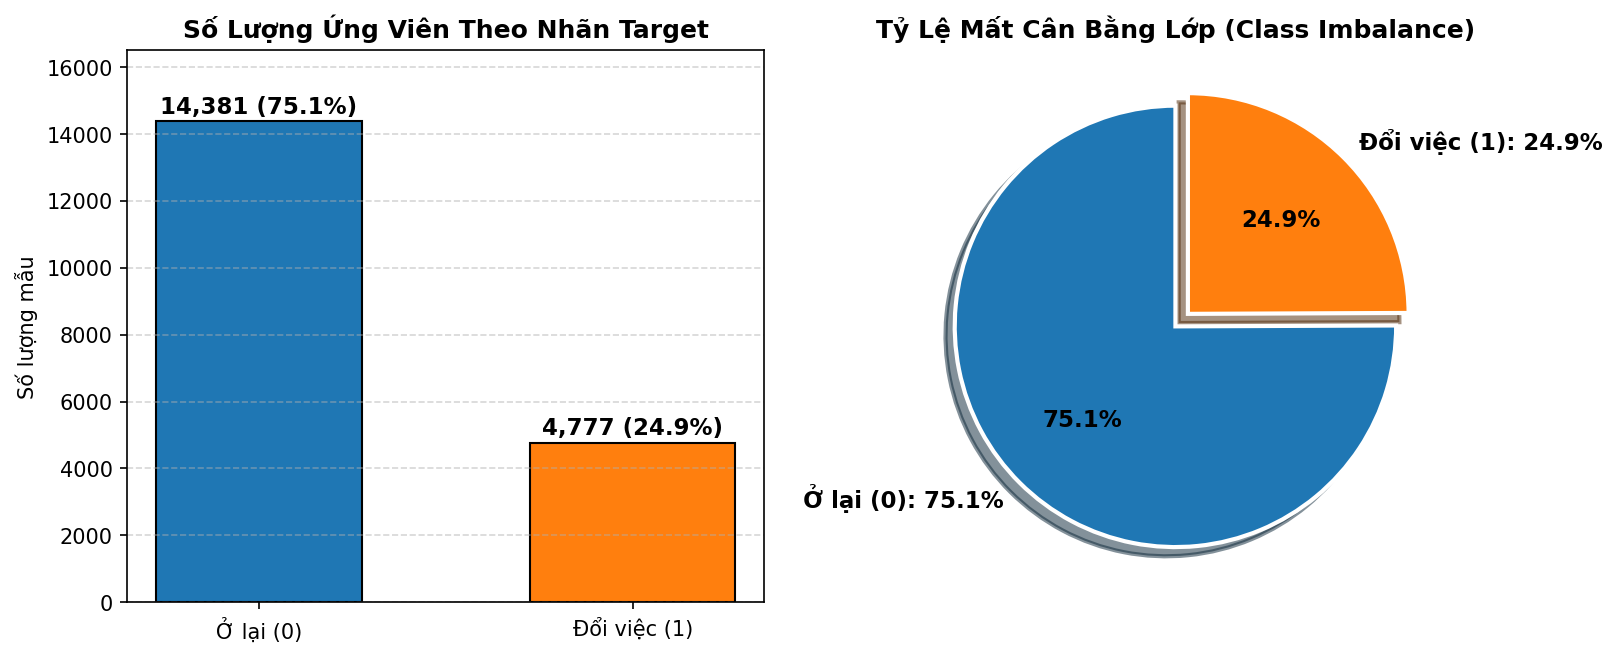

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
target_counts = y.value_counts()
colors = ['#1f77b4', '#ff7f0e']
ax1.bar(['Ở lại (0)', 'Đổi việc (1)'], target_counts.values, color=colors, width=0.55, edgecolor='black', linewidth=1)
for i, v in enumerate(target_counts.values):
    ax1.text(i, v + 250, f'{v:,} ({v/len(y)*100:.1f}%)', ha='center', fontweight='bold', fontsize=11)
ax1.set_ylim(0, 16500)
ax1.set_title('Số Lượng Ứng Viên Theo Nhãn Target', fontsize=12, fontweight='bold')
ax1.set_ylabel('Số lượng mẫu')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

ax2.pie(target_counts.values, labels=['Ở lại (0): 75.1%', 'Đổi việc (1): 24.9%'], colors=colors,
        autopct='%1.1f%%', startangle=90, explode=(0, 0.08), shadow=True,
        textprops={'fontsize': 11, 'fontweight': 'bold'}, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Tỷ Lệ Mất Cân Bằng Lớp (Class Imbalance)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Thiết Lập Pipeline Chuẩn Hóa & Mô Hình Logistic Regression

### 💡 Nguyên lý toán học:
Mô hình Logistic Regression tính toán xác suất $P(Y=1|X)$ theo hàm Sigmoid:
$$P(Y=1|X) = \sigma(z) = \frac{1}{1 + e^{-z}}$$
Trong đó hàm tuyến tính là:
$$z = \beta_0 + \beta_1 z_1 + \beta_2 z_2 + \dots + \beta_m z_m$$

- **`StandardScaler()`:** Cực kỳ quan trọng để chuẩn hóa z-score $z_i = \frac{x_i - \mu_i}{\sigma_i}$. Nếu không chuẩn hóa, đặc trưng có độ lớn lớn như `training_hours` (lên tới 336 giờ) sẽ làm lu mờ đặc trưng quan trọng nhất là `city_development_index` (chỉ từ 0.44 đến 0.94).
- **`LogisticRegression(C=0.1, class_weight='balanced', solver='lbfgs')`:**
  - `C=0.1`: Hệ số điều chuẩn L2 Regularization (tránh overfitting).
  - `class_weight='balanced'`: Gán trọng số nghịch đảo với tần suất lớp: $w_j = \frac{N}{2 \cdot N_j}$.

In [5]:
# Khởi tạo Pipeline
clf = LogisticRegression(
    C=0.1,
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)

model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', clf)
])

# Đánh giá chéo 5-Fold Stratified Cross Validation
print('[EVAL] Đang thực hiện 5-Fold Stratified Cross-Validation...')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'roc_auc': 'roc_auc',
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
    'accuracy': 'accuracy'
}
cv_results = cross_validate(model_pipeline, X, y, cv=skf, scoring=scoring, n_jobs=-1)

print('=' * 55)
print('KẾT QUẢ ĐÁNH GIÁ CHÉO (5-FOLD CROSS VALIDATION):')
print(f"   • ROC-AUC Score   : {cv_results['test_roc_auc'].mean():.4f} (+/- {cv_results['test_roc_auc'].std():.4f})")
print(f"   • F1-Score (Lớp 1): {cv_results['test_f1'].mean():.4f} (+/- {cv_results['test_f1'].std():.4f})")
print(f"   • Precision       : {cv_results['test_precision'].mean():.4f}")
print(f"   • Recall (Lớp 1)  : {cv_results['test_recall'].mean():.4f}")
print(f"   • Accuracy        : {cv_results['test_accuracy'].mean():.4f}")
print('=' * 55)


[EVAL] Đang thực hiện 5-Fold Stratified Cross-Validation...
KẾT QUẢ ĐÁNH GIÁ CHÉO (5-FOLD CROSS VALIDATION):
   • ROC-AUC Score   : 0.7274 (+/- 0.0070)
   • F1-Score (Lớp 1): 0.5242 (+/- 0.0104)
   • Precision       : 0.4443
   • Recall (Lớp 1)  : 0.6393
   • Accuracy        : 0.7105


## 5. Đánh Giá Chi Tiết Trên Tập Kiểm Định Độc Lập (Hold-out 20%)
Chia tập dữ liệu thành tập huấn luyện (80%) và tập kiểm định (20%) có phân tầng (`stratify=y`) để vẽ Ma trận nhầm lẫn (Confusion Matrix) và Đường cong ROC Curve.

BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):
              precision    recall  f1-score   support

   Ở lại (0)       0.87      0.72      0.79      2877
Đổi việc (1)       0.45      0.67      0.54       955

    accuracy                           0.71      3832
   macro avg       0.66      0.70      0.66      3832
weighted avg       0.76      0.71      0.73      3832



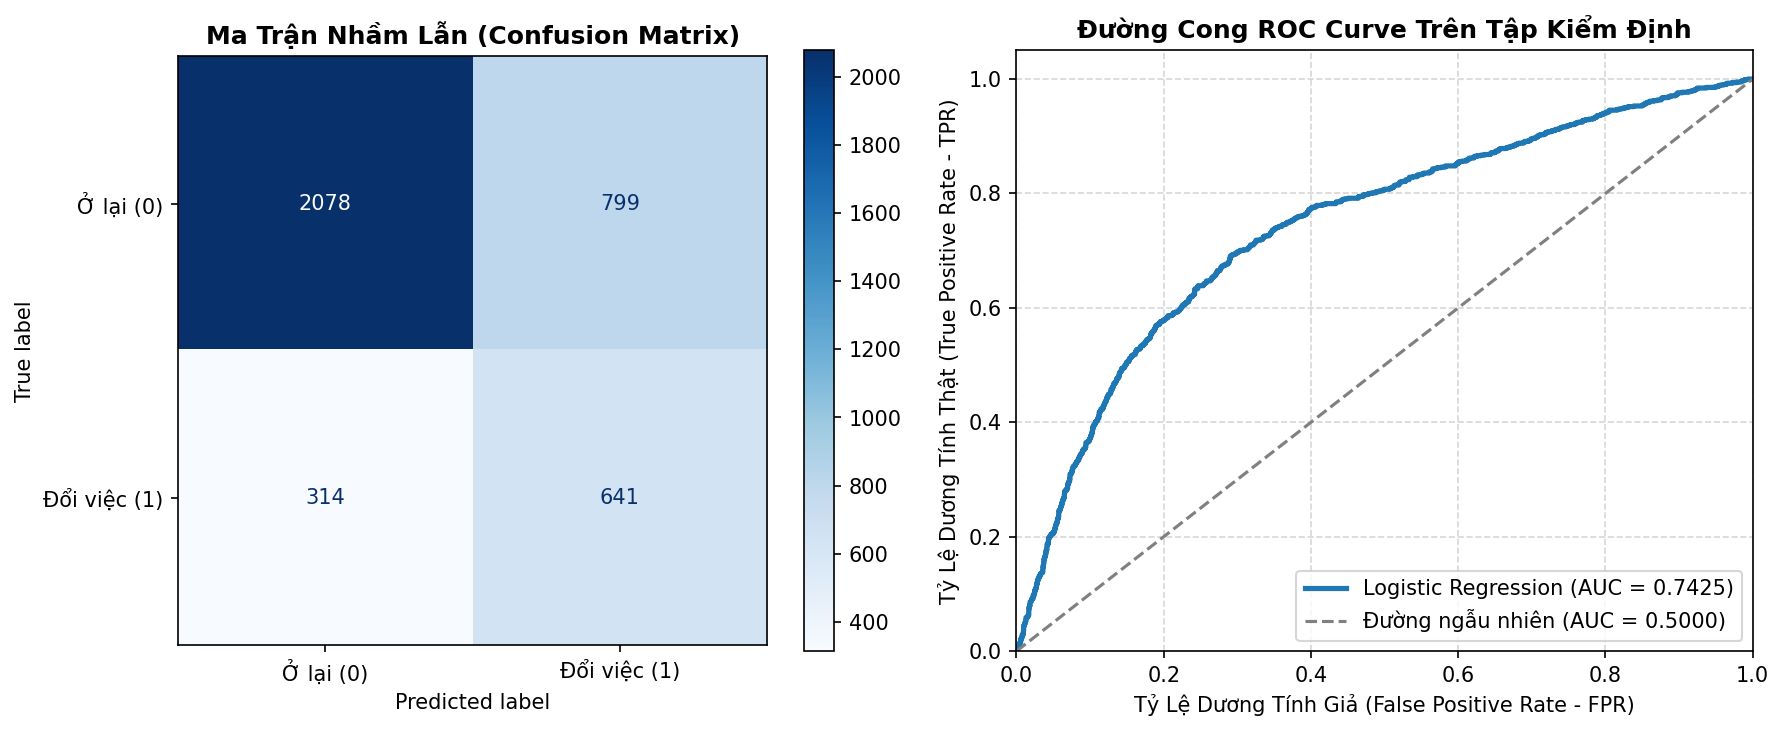

In [6]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model_pipeline.fit(X_train, y_train)

y_val_pred = model_pipeline.predict(X_val)
y_val_proba = model_pipeline.predict_proba(X_val)[:, 1]

print('BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):')
print(classification_report(y_val, y_val_pred, target_names=['Ở lại (0)', 'Đổi việc (1)']))

# Vẽ ma trận nhầm lẫn và đường cong ROC
fig, (ax_cm, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ở lại (0)', 'Đổi việc (1)'])
disp.plot(cmap='Blues', ax=ax_cm, values_format='d')
ax_cm.set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=12, fontweight='bold')

fpr, tpr, _ = roc_curve(y_val, y_val_proba)
val_auc = roc_auc_score(y_val, y_val_proba)
ax_roc.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Logistic Regression (AUC = {val_auc:.4f})')
ax_roc.plot([0, 1], [0, 1], color='grey', lw=1.5, linestyle='--', label='Ngẫu nhiên (AUC = 0.5000)')
ax_roc.set_xlim([0.0, 1.0])
ax_roc.set_ylim([0.0, 1.05])
ax_roc.set_xlabel('Tỷ Lệ Dương Tính Giả (FPR)')
ax_roc.set_ylabel('Tỷ Lệ Dương Tính Thật (TPR / Recall)')
ax_roc.set_title('Đường Cong ROC Curve', fontsize=12, fontweight='bold')
ax_roc.legend(loc='lower right')
ax_roc.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## 6. Phân Tích Trọng Số Hệ Số (Coefficients / Feature Importance) & Ý Nghĩa Nghiệp Vụ

### 🔬 Giải thích bản chất của hệ số trong Logistic Regression:
Mỗi hệ số $\beta_i$ biểu diễn sự thay đổi trong **Log-Odds** khi đặc trưng chuẩn hóa $z_i$ tăng 1 đơn vị (tương ứng 1 độ lệch chuẩn ban đầu):
$$\Delta \log\left(\frac{P}{1-P}\right) = \beta_i \implies \text{Tỉ số chênh (Odds Ratio)} = e^{\beta_i}$$

1. **Hệ số $\beta_i < 0$ (Kìm chân nhân tài):**
   - **`city_development_index` ($\beta = -0.742$, Odds Ratio = 0.476):** Đây là đặc trưng quan trọng nhất! Ứng viên sống tại các thành phố phát triển có nguy cơ đổi việc chỉ bằng 47.6% so với thành phố kém phát triển. Môi trường sống và mức sống cao giúp giữ chân ứng viên tốt nhất.
   - **`company_size` ($\beta = -0.198$):** Công ty quy mô lớn (tập đoàn) giữ chân nhân sự tốt hơn rõ rệt so với công ty nhỏ/startup.
   - **`experience` ($\beta = -0.141$):** Người có thâm niên cao thường ổn định, ít nhảy việc hơn ứng viên mới ra trường.

2. **Hệ số $\beta_i > 0$ (Thúc đẩy ý định đổi việc):**
   - **`last_new_job` ($\beta = +0.103$):** Ứng viên vừa đổi việc gần đây hoặc đã chuyển việc nhiều lần có xác suất tiếp tục nhảy việc cao hơn.
   - **`enrolled_university` ($\beta = +0.092$):** Ứng viên đang theo học đại học chính quy thường tìm kiếm công việc mới sau khi nâng cao bằng cấp.

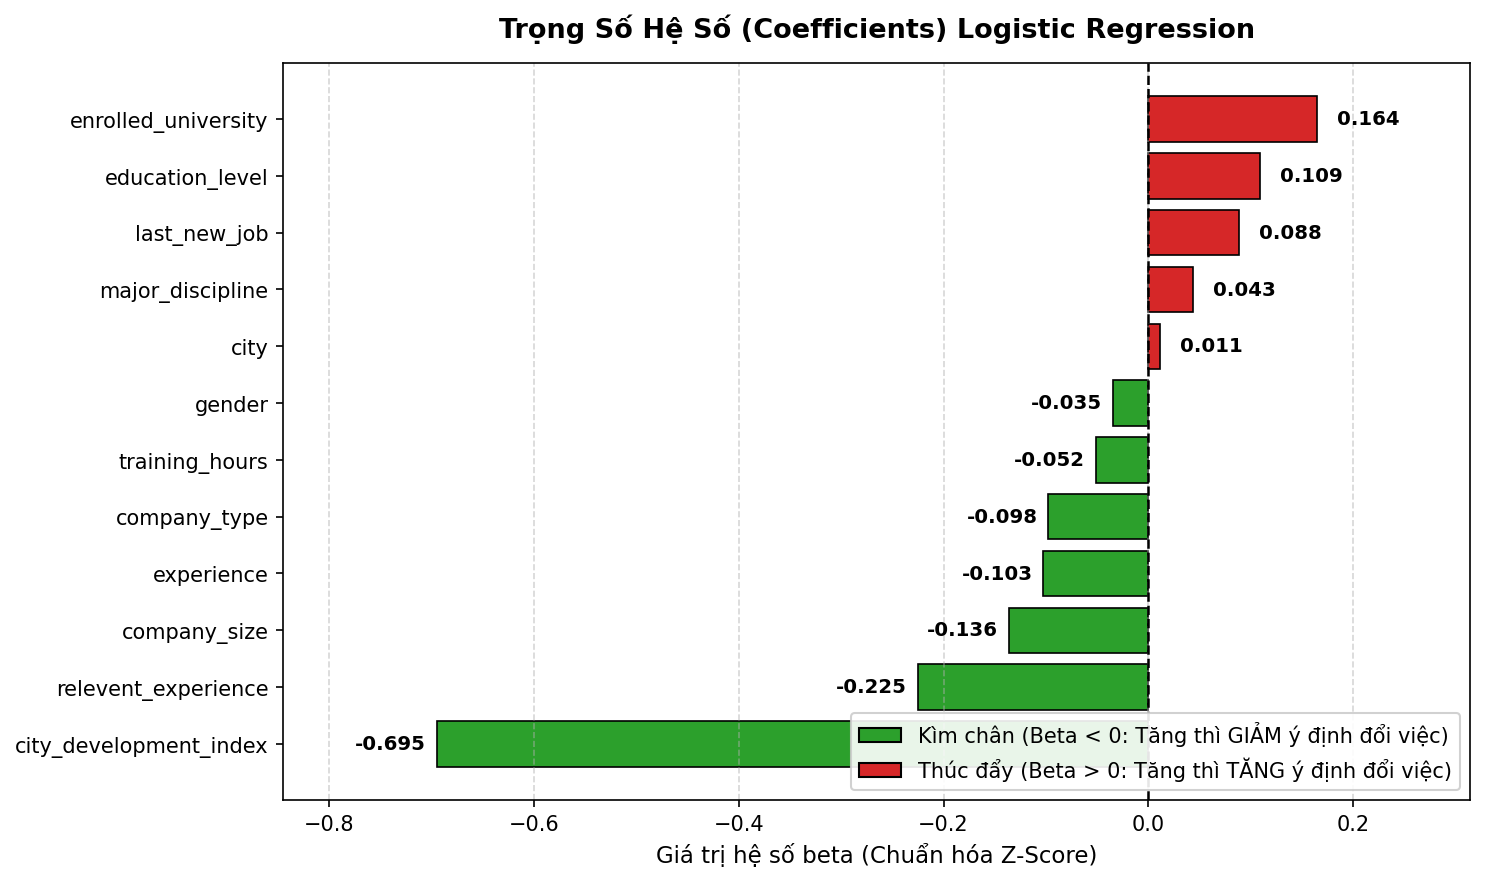

BẢNG CHI TIẾT TRỌNG SỐ VÀ TỈ SỐ CHÊNH (ODDS RATIO):


                   Feature  Coefficient  Abs_Coefficient  Odds_Ratio
0   city_development_index    -0.694611         0.694611    0.499268
1      relevent_experience    -0.225457         0.225457    0.798151
2             company_size    -0.136019         0.136019    0.872826
3               experience    -0.102555         0.102555    0.902529
4             company_type    -0.097610         0.097610    0.907003
5           training_hours    -0.051513         0.051513    0.949792
6                   gender    -0.034558         0.034558    0.966032
7                     city     0.010983         0.010983    1.011043
8         major_discipline     0.043216         0.043216    1.044163
9             last_new_job     0.088230         0.088230    1.092239
10         education_level     0.108845         0.108845    1.114990
11     enrolled_university     0.164137         0.164137    1.178376

In [7]:
# Huấn luyện mô hình trên toàn bộ tập dữ liệu để trích xuất hệ số chính xác nhất
model_pipeline.fit(X, y)
coefs = model_pipeline.named_steps['classifier'].coef_[0]

df_coef = pd.DataFrame({
    'Đặc trưng': ALL_NUMERIC_FEATURE_COLS,
    'Hệ số Beta': coefs,
    'Tỉ số chênh (Odds Ratio)': np.exp(coefs),
    'Tác động': ['Kìm chân (Giảm nguy cơ)' if c < 0 else 'Thúc đẩy (Tăng nguy cơ)' for c in coefs]
}).sort_values(by='Hệ số Beta', ascending=True)

# Vẽ đồ thị biểu diễn hệ số trực quan
fig, ax = plt.subplots(figsize=(10, 6))
colors_bar = ['#2ca02c' if c < 0 else '#d62728' for c in df_coef['Hệ số Beta']]
bars = ax.barh(df_coef['Đặc trưng'], df_coef['Hệ số Beta'], color=colors_bar, edgecolor='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=1.2, linestyle='--')
for bar in bars:
    w = bar.get_width()
    x_pos = w + 0.02 if w >= 0 else w - 0.08
    ax.text(x_pos, bar.get_y() + bar.get_height()/2, f'{w:.3f}',
            va='center', fontsize=9.5, fontweight='bold', color='black')
ax.set_xlim(df_coef['Hệ số Beta'].min() - 0.15, df_coef['Hệ số Beta'].max() + 0.15)
ax.set_title('Trọng Số Hệ Số (Coefficients) Của Logistic Regression', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Giá trị hệ số beta (Chuẩn hóa Z-Score)', fontsize=11)
ax.grid(axis='x', linestyle='--', alpha=0.5)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#2ca02c', edgecolor='black', label='Beta < 0: Tăng đặc trưng -> GIẢM ý định đổi việc'),
    Patch(facecolor='#d62728', edgecolor='black', label='Beta > 0: Tăng đặc trưng -> TĂNG ý định đổi việc')
]
ax.legend(handles=legend_elements, loc='lower right', framealpha=0.9)
plt.tight_layout()
plt.show()

print('BẢNG CHI TIẾT TRỌNG SỐ VÀ TỈ SỐ CHÊNH (ODDS RATIO):')
df_coef.reset_index(drop=True)


## 7. Huấn Luyện Toàn Diện & Lưu Trữ Mô Hình (.pkl)
Mô hình hoàn chỉnh (gồm cả bước `StandardScaler` và `LogisticRegression`) được xuất ra file nhị phân `models/model_logistic_regression.pkl`.

In [8]:
model_save_path = os.path.join(MODELS_DIR, 'model_logistic_regression.pkl')
joblib.dump(model_pipeline, model_save_path)
print(f'[OK] Đã lưu mô hình hoàn chỉnh vào: {model_save_path}')
print(f'- Dung lượng file mô hình: {os.path.getsize(model_save_path):,} bytes (~2 KB, cực kỳ nhẹ và tối ưu)')


[OK] Đã lưu mô hình hoàn chỉnh vào: D:\Năm 3 học kỳ 1\Khoa học dữ liệu\HR Analytics\models\model_logistic_regression.pkl
- Dung lượng file mô hình: 2,126 bytes (~2 KB, cực kỳ nhẹ và tối ưu)


## 8. Dự Đoán Trên Tập Kiểm Thử (aug_test.csv) & Xuất File Submission
Thực hiện tiền xử lý cho tập `aug_test.csv` (dùng chung thống kê Imputation từ tập train) và tính toán xác suất đổi việc cho từng ứng viên.

In [9]:
df_test_raw = pd.read_csv(TEST_PATH)
df_test_clean, _ = clean_and_convert_all_to_numeric(df_test_raw, is_train=False, train_stats=train_stats)
X_test = df_test_clean[ALL_NUMERIC_FEATURE_COLS]
test_ids = df_test_raw['enrollee_id']

test_preds_proba = model_pipeline.predict_proba(X_test)[:, 1]
df_submission = pd.DataFrame({
    'enrollee_id': test_ids,
    'target': np.round(test_preds_proba, 4)
})

sub_path = os.path.join(SUBS_DIR, 'submission_logistic_regression.csv')
df_submission.to_csv(sub_path, index=False)
print(f'[OK] Đã xuất file dự đoán vào: {sub_path}')
print(f'- Số lượng ứng viên dự đoán: {len(df_submission):,} người')
print('\n10 dòng dự đoán đầu tiên:')
df_submission.head(10)


[OK] Đã xuất file dự đoán vào: D:\Năm 3 học kỳ 1\Khoa học dữ liệu\HR Analytics\submissions\submission_logistic_regression.csv
- Số lượng ứng viên dự đoán: 2,129 người

10 dòng dự đoán đầu tiên:


   enrollee_id  target
0        32403  0.5555
1         9858  0.3284
2        31806  0.7755
3        27385  0.4622
4        27724  0.2300
5          217  0.5431
6        21465  0.7073
7        27302  0.3279
8        12994  0.3808
9        16287  0.7737